In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import json

RUNS = Path("..") / "runs"
runs = sorted(RUNS.glob("*_mlp_seed*"))
print(runs)                    

rows = []
for run_dir in runs:

    with open(run_dir / "config.json") as f:
        seed = json.load(f)["seed"]

    df = pd.read_csv(run_dir / "metrics.csv")                
    memorise_epoch = df.loc[df["train_acc"] >= 0.99, "epoch"].iloc[0]
    grok_epoch = df.loc[df["test_acc"] >= 0.99, "epoch"].iloc[0]
    rows.append({"seed": seed, "memorise_epoch": memorise_epoch, "grok_epoch": grok_epoch})

table = pd.DataFrame(rows)
table

[PosixPath('../runs/2026-11-03_00-56-29_mlp_seed42'), PosixPath('../runs/2026-11-13_20-47-41_mlp_seed0'), PosixPath('../runs/2026-11-13_21-02-51_mlp_seed1')]


,seed,memorise_epoch,grok_epoch
0,42,180,990
1,0,180,980
2,1,190,1040


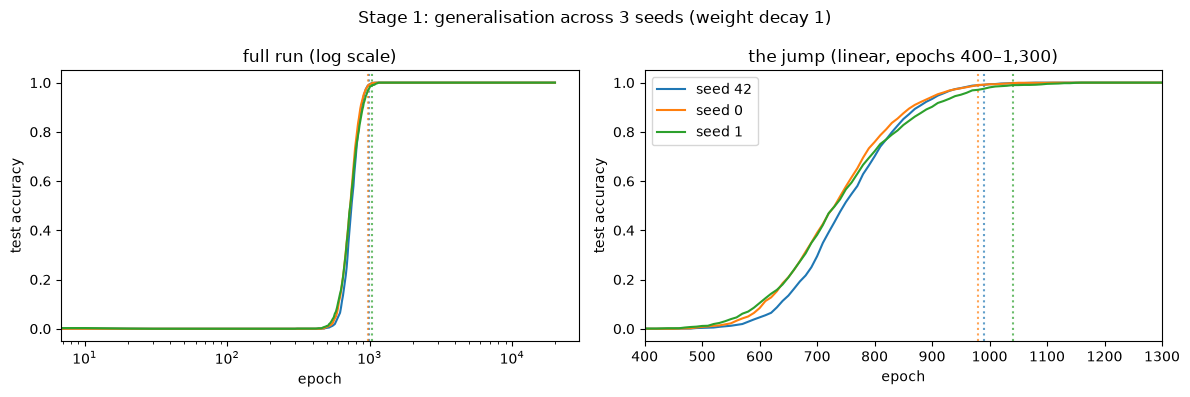

In [3]:
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(12, 4))

for run_dir, (_, row) in zip(runs, table.iterrows()):
    df = pd.read_csv(run_dir / "metrics.csv")
    for ax in (ax_full, ax_zoom):
        line, = ax.plot(df["epoch"], df["test_acc"], label=f"seed {row['seed']}")
        ax.axvline(row["grok_epoch"], color=line.get_color(), linestyle=":", alpha=0.7)

ax_full.set_xscale("log")
ax_full.set_title("full run (log scale)")

ax_zoom.set_xlim(400, 1300)
ax_zoom.set_title("the jump (linear, epochs 400–1,300)")

for ax in (ax_full, ax_zoom):
    ax.set_xlabel("epoch")
    ax.set_ylabel("test accuracy")
ax_zoom.legend()

fig.suptitle("Stage 1: generalisation across 3 seeds (weight decay 1)")
plt.tight_layout()
plt.savefig("figures/stage1_seeds.png", dpi=200)
plt.show()